In [10]:
import heapq
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warehouse = pd.read_csv("warehouse_grid.csv")

rows = int(warehouse["row"].max()) + 1
cols = int(warehouse["col"].max()) + 1

warehouse_grid = np.full((rows, cols), "free", dtype=object)

for r in warehouse.itertuples(index=False):
    warehouse_grid[int(r.row), int(r.col)] = r.cell_type

dock = tuple(
    warehouse.loc[warehouse["cell_type"] == "dock", ["row", "col"]]
    .iloc[0]
    .astype(int)
)

pickup_data = warehouse[warehouse["cell_type"] == "pickup"].copy()
pickup_data["num"] = pickup_data["label"].str.extract(r"(\d+)").astype(int)
pickup_data = pickup_data.sort_values("num")

pickup_points = {
    r.label: (int(r.row), int(r.col))
    for r in pickup_data.itertuples()
}

print("Warehouse size:", rows, "x", cols)
print("Total cells:", len(warehouse))
print("\nCell counts:")
print(warehouse["cell_type"].value_counts())
print("\nDock:", dock)
print("Pickup points:", pickup_points)


Warehouse size: 30 x 50
Total cells: 1500

Cell counts:
cell_type
free      1009
shelf      480
pickup      10
dock         1
Name: count, dtype: int64

Dock: (15, 0)
Pickup points: {'P1': (2, 21), 'P2': (2, 30), 'P3': (3, 1), 'P4': (6, 1), 'P5': (11, 16), 'P6': (11, 18), 'P7': (16, 24), 'P8': (18, 10), 'P9': (20, 21), 'P10': (21, 28)}


In [11]:
def heuristic(current, goal):
    return abs(current[0] - goal[0]) + abs(current[1] - goal[1])


def valid_moves(board, position):
    r, c = position
    moves = []

    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc

        if 0 <= nr < board.shape[0] and 0 <= nc < board.shape[1]:
            if board[nr, nc] != "shelf":
                moves.append((nr, nc))

    return moves


def reconstruct_path(parent, start, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        if current == start:
            break
        current = parent[current]

    path.reverse()
    return path if path and path[0] == start else None


print("Manhattan distance Dock -> P1:",
      heuristic(dock, pickup_points["P1"]))


Manhattan distance Dock -> P1: 34


In [12]:
def uniform_cost_search(board, start, goal):
    begin = time.perf_counter()

    queue = [(0, start, [start])]
    best_cost = {start: 0}
    visited = set()
    nodes_expanded = 0

    while queue:
        cost, current, path = heapq.heappop(queue)

        if current in visited:
            continue

        visited.add(current)
        nodes_expanded += 1

        if current == goal:
            return {
                "path": path,
                "distance": cost,
                "expanded": nodes_expanded,
                "time": (time.perf_counter() - begin) * 1000
            }

        for next_cell in valid_moves(board, current):
            new_cost = cost + 1

            if new_cost < best_cost.get(next_cell, float("inf")):
                best_cost[next_cell] = new_cost
                heapq.heappush(
                    queue,
                    (new_cost, next_cell, path + [next_cell])
                )

    return None


def greedy_search(board, start, goal):
    begin = time.perf_counter()

    queue = [(heuristic(start, goal), start, [start], 0)]
    visited = set()
    nodes_expanded = 0

    while queue:
        _, current, path, cost = heapq.heappop(queue)

        if current in visited:
            continue

        visited.add(current)
        nodes_expanded += 1

        if current == goal:
            return {
                "path": path,
                "distance": cost,
                "expanded": nodes_expanded,
                "time": (time.perf_counter() - begin) * 1000
            }

        for next_cell in valid_moves(board, current):
            if next_cell not in visited:
                heapq.heappush(
                    queue,
                    (
                        heuristic(next_cell, goal),
                        next_cell,
                        path + [next_cell],
                        cost + 1
                    )
                )

    return None


def a_star(board, start, goal):
    begin = time.perf_counter()

    cost_so_far = {start: 0}
    queue = [(heuristic(start, goal), start, [start])]
    visited = set()
    nodes_expanded = 0

    while queue:
        _, current, path = heapq.heappop(queue)

        if current in visited:
            continue

        visited.add(current)
        nodes_expanded += 1

        if current == goal:
            return {
                "path": path,
                "distance": cost_so_far[current],
                "expanded": nodes_expanded,
                "time": (time.perf_counter() - begin) * 1000
            }

        for next_cell in valid_moves(board, current):
            new_g = cost_so_far[current] + 1

            if new_g < cost_so_far.get(next_cell, float("inf")):
                cost_so_far[next_cell] = new_g

                new_f = new_g + heuristic(next_cell, goal)

                heapq.heappush(
                    queue,
                    (
                        new_f,
                        next_cell,
                        path + [next_cell]
                    )
                )

    return None


In [13]:
target = pickup_points["P1"]

ucs_result = uniform_cost_search(warehouse_grid, dock, target)
greedy_result = greedy_search(warehouse_grid, dock, target)
astar_result = a_star(warehouse_grid, dock, target)

print("=" * 55)
print("DOCK -> P1 RESULTS")
print("=" * 55)

for name, result in [
    ("Uniform Cost Search", ucs_result),
    ("Greedy Best-First Search", greedy_result),
    ("A* Search", astar_result)
]:
    print(f"\n{name}")
    print("Path Length:", result["distance"])
    print("Nodes Expanded:", result["expanded"])
    print("Execution Time: {:.3f} ms".format(result["time"]))


DOCK -> P1 RESULTS

Uniform Cost Search
Path Length: 34
Nodes Expanded: 481
Execution Time: 2.036 ms

Greedy Best-First Search
Path Length: 36
Nodes Expanded: 37
Execution Time: 0.197 ms

A* Search
Path Length: 34
Nodes Expanded: 47
Execution Time: 0.267 ms


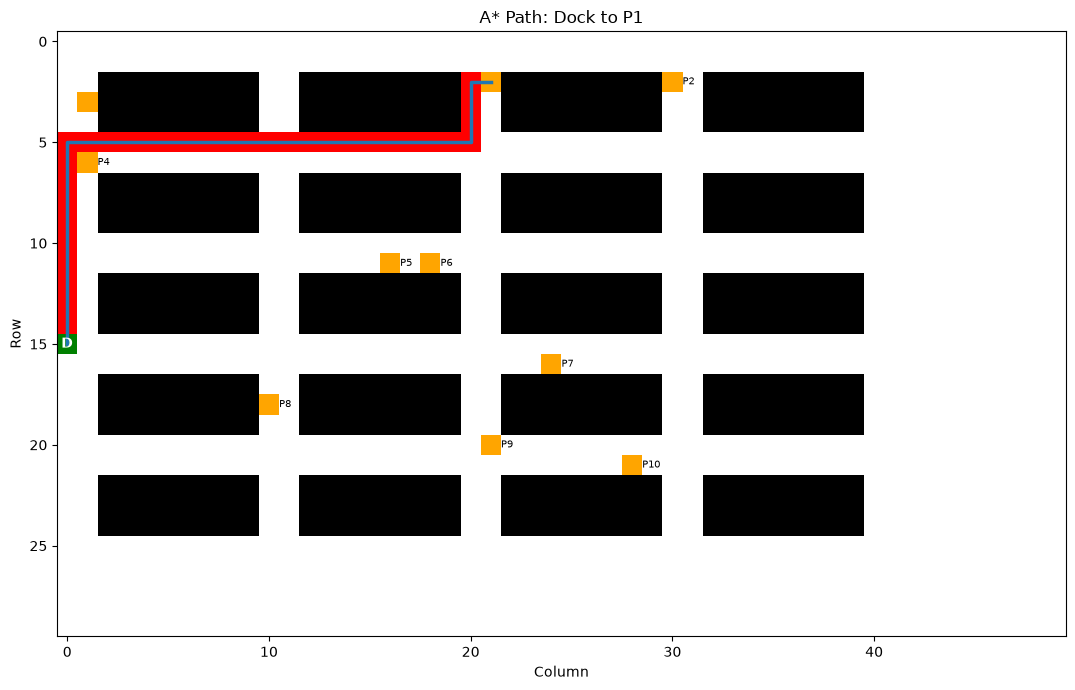

In [14]:
def show_warehouse(board, start, targets, route=None, heading="Warehouse Layout", save_name=None):
    values = {
        "free": 0,
        "shelf": 1,
        "dock": 2,
        "pickup": 3,
        "route": 4
    }

    image = np.zeros(board.shape)

    for r in range(board.shape[0]):
        for c in range(board.shape[1]):
            image[r, c] = values.get(board[r, c], 0)

    if route:
        for r, c in route:
            if board[r, c] not in ["dock", "pickup"]:
                image[r, c] = values["route"]

    cmap = ListedColormap(["white", "black", "green", "orange", "red"])

    plt.figure(figsize=(13, 7))
    plt.imshow(image, cmap=cmap, origin="upper", vmin=0, vmax=4)

    plt.text(
        start[1], start[0], "D",
        ha="center", va="center",
        color="white", fontweight="bold"
    )

    for label, (r, c) in targets.items():
        plt.text(c + 0.5, r, label, fontsize=7, va="center")

    if route:
        rr = [p[0] for p in route]
        cc = [p[1] for p in route]
        plt.plot(cc, rr, linewidth=2.5)

    plt.title(heading)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.tight_layout()

    if save_name:
        plt.savefig(save_name, dpi=200, bbox_inches="tight")

    plt.show()
    plt.close()


show_warehouse(
    warehouse_grid,
    dock,
    pickup_points,
    route=astar_result["path"],
    heading="A* Path: Dock to P1",
    save_name="P1_astar_route.png"
)


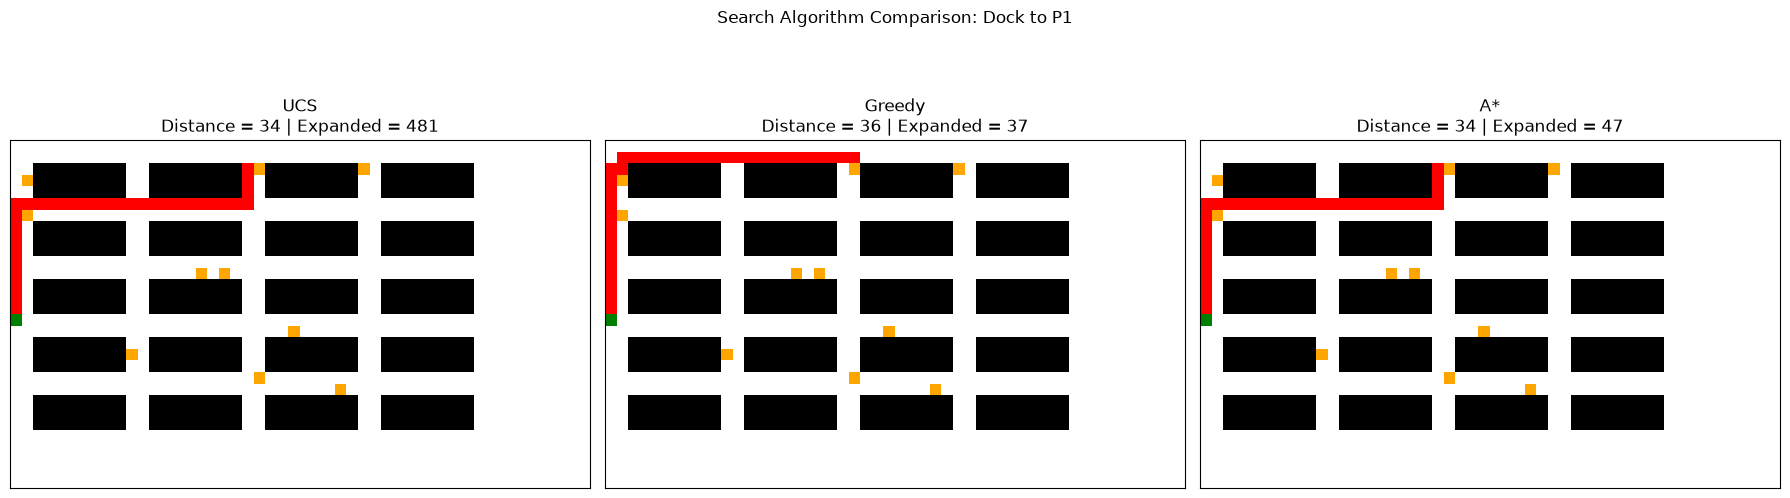

In [15]:
# Compare UCS, Greedy and A*

comparison_results = [
    ("UCS", ucs_result),
    ("Greedy", greedy_result),
    ("A*", astar_result)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

values = {
    "free": 0,
    "shelf": 1,
    "dock": 2,
    "pickup": 3,
    "route": 4
}

cmap = ListedColormap(["white", "black", "green", "orange", "red"])

for axis, (name, result) in zip(axes, comparison_results):
    image = np.zeros(warehouse_grid.shape)

    for r in range(rows):
        for c in range(cols):
            image[r, c] = values.get(warehouse_grid[r, c], 0)

    for r, c in result["path"]:
        if warehouse_grid[r, c] not in ["dock", "pickup"]:
            image[r, c] = 4

    axis.imshow(image, cmap=cmap, origin="upper", vmin=0, vmax=4)
    axis.set_title(
        f"{name}\n"
        f"Distance = {result['distance']} | "
        f"Expanded = {result['expanded']}"
    )
    axis.set_xticks([])
    axis.set_yticks([])

plt.suptitle("Search Algorithm Comparison: Dock to P1")
plt.tight_layout()
plt.savefig("P1_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()


In [16]:
# Run all pickup locations

methods = {
    "UCS": uniform_cost_search,
    "Greedy": greedy_search,
    "A*": a_star
}

benchmark = []

for label, destination in pickup_points.items():
    for method_name, method in methods.items():
        result = method(warehouse_grid, dock, destination)

        benchmark.append({
            "Pickup": label,
            "Algorithm": method_name,
            "Path Length": result["distance"],
            "Nodes Expanded": result["expanded"],
            "Time (ms)": round(result["time"], 3)
        })

benchmark_df = pd.DataFrame(benchmark)

display(benchmark_df)

benchmark_df.to_csv("search_results.csv", index=False)


,Pickup,Algorithm,Path Length,Nodes Expanded,Time (ms)
0,P1,UCS,34,481,1.157
1,P1,Greedy,36,37,0.099
2,P1,A*,34,47,0.187
3,P2,UCS,43,640,1.814
4,P2,Greedy,45,46,0.125
5,P2,A*,43,62,0.184
6,P3,UCS,13,103,0.237
7,P3,Greedy,13,14,0.029
8,P3,A*,13,14,0.046
9,P4,UCS,10,65,0.139


In [17]:
# Comparison and averages

path_table = benchmark_df.pivot(
    index="Pickup",
    columns="Algorithm",
    values="Path Length"
)[["UCS", "Greedy", "A*"]]

path_table["A* Optimal"] = path_table["A*"] == path_table["UCS"]

print("PATH OPTIMALITY")
display(path_table)

node_table = benchmark_df.pivot(
    index="Pickup",
    columns="Algorithm",
    values="Nodes Expanded"
)[["UCS", "Greedy", "A*"]]

print("NODE EXPANSION")
display(node_table)

average_results = (
    benchmark_df
    .groupby("Algorithm")
    .agg(
        Average_Path_Length=("Path Length", "mean"),
        Average_Nodes_Expanded=("Nodes Expanded", "mean"),
        Average_Time_ms=("Time (ms)", "mean")
    )
    .reindex(["UCS", "Greedy", "A*"])
    .round(2)
)

print("AVERAGE PERFORMANCE")
display(average_results)

average_results.to_csv("average_results.csv")


PATH OPTIMALITY


Algorithm,UCS,Greedy,A*,A* Optimal
Pickup,,,,
P1,34,36,34,True
P10,34,38,34,True
P2,43,45,43,True
P3,13,13,13,True
P4,10,10,10,True
P5,20,20,20,True
P6,22,22,22,True
P7,25,25,25,True
P8,13,13,13,True


NODE EXPANSION


Algorithm,UCS,Greedy,A*
Pickup,,,
P1,481,37,47
P10,492,42,134
P2,640,46,62
P3,103,14,14
P4,65,11,11
P5,230,21,21
P6,265,23,23
P7,325,26,50
P8,113,14,28


AVERAGE PERFORMANCE


,Average_Path_Length,Average_Nodes_Expanded,Average_Time_ms
Algorithm,,,
UCS,24.0,305.7,0.75
Greedy,24.8,26.1,0.07
A*,24.0,47.4,0.14


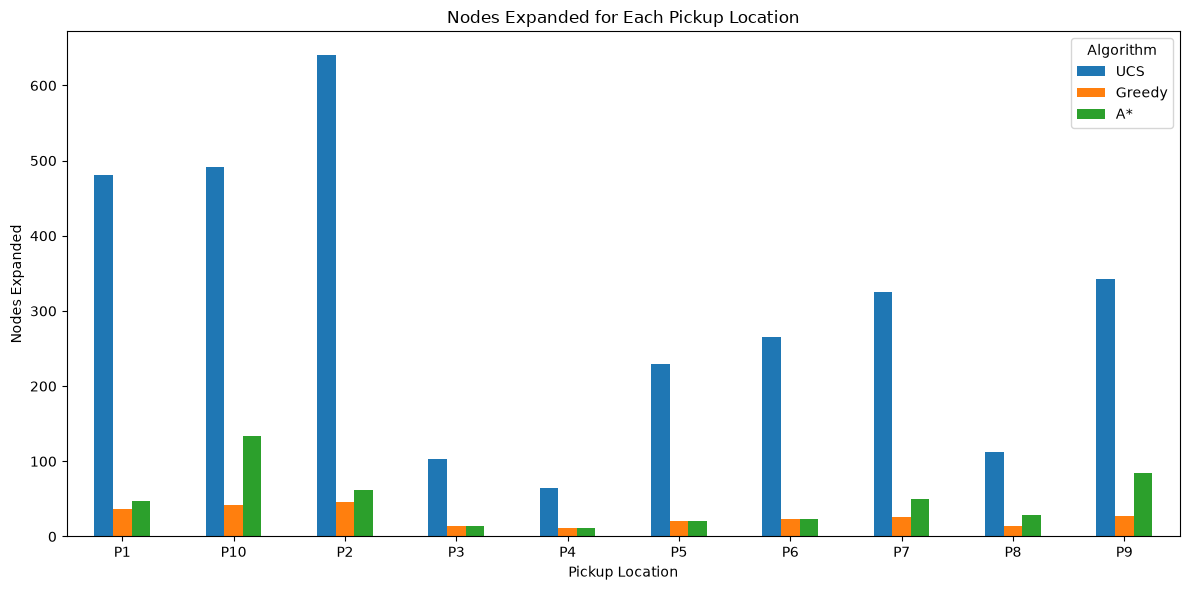

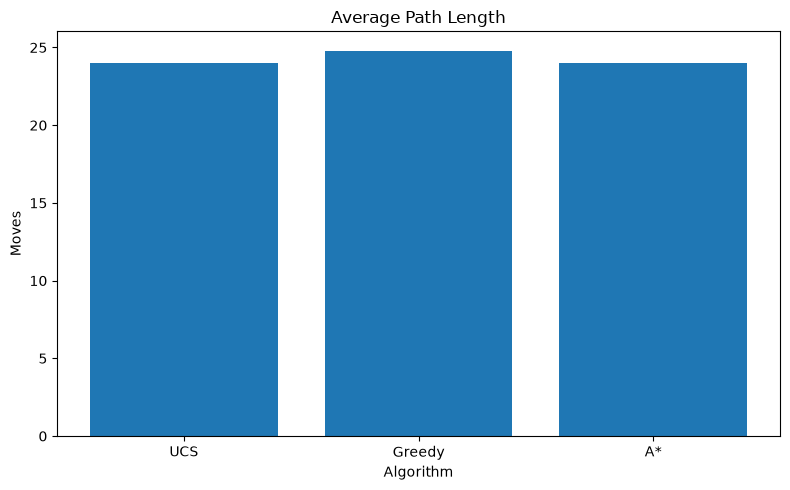

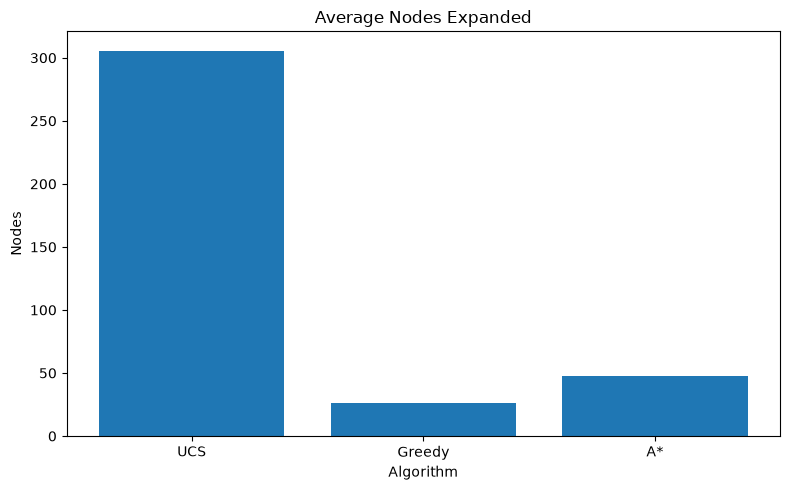

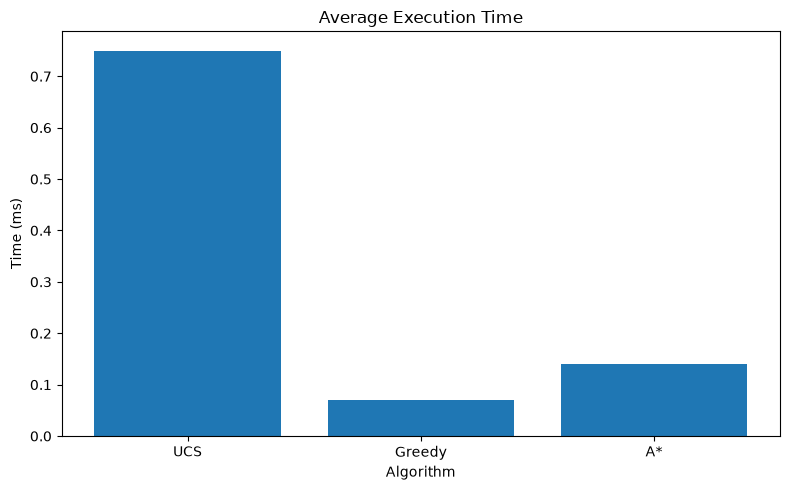

All results and diagrams generated.


In [18]:
# Final performance graphs

node_table.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Nodes Expanded for Each Pickup Location")
plt.xlabel("Pickup Location")
plt.ylabel("Nodes Expanded")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("nodes_expanded_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

for column, title, ylabel, filename in [
    ("Average_Path_Length", "Average Path Length", "Moves", "average_path_length.png"),
    ("Average_Nodes_Expanded", "Average Nodes Expanded", "Nodes", "average_nodes_expanded.png"),
    ("Average_Time_ms", "Average Execution Time", "Time (ms)", "average_execution_time.png")
]:
    plt.figure(figsize=(8, 5))
    plt.bar(average_results.index, average_results[column])
    plt.title(title)
    plt.xlabel("Algorithm")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

print("All results and diagrams generated.")
